# EDA — the transaction graph

- **What:** the transactions per day around the cut, the size of the HI-Small transaction graph, its self-loops and its degree distribution.
- **Needs:** `data/raw/HI-Small_Trans.csv` and the cut-off date in `conf/prepare_data.yaml`.
- **Produces:** the figure `data_daily_transactions.pdf` (thesis section 4.1), the numbers of thesis section 4.2 and the figure `data_degree_distribution.pdf`.
- Nodes are accounts and edges are transactions, exactly as `prepare_data.py` builds the graph.

## 1. Setup

- Imports, the thesis figure style, the paths.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

ROOT = '..'                                                          # the repository
FIGURES = '../../gnn_for_fraudulent_patterns/thesis/figures'         # where the thesis reads its figures

plt.style.use('thesis_figures.mplstyle')
pd.set_option('display.float_format', lambda value: f'{value:,.2f}')

## 2. Load the transactions

- Same rows and order as `prepare_data.load_raw`: transactions before the cut-off, sorted by time.
- An account is identified by its account number, as in the pipeline.

In [2]:
cutoff = yaml.safe_load(open(f'{ROOT}/conf/prepare_data.yaml'))['cutoff']
columns = ['Timestamp', 'src_bank', 'src_account', 'dst_bank', 'dst_account', 'Amount Received', 'Receiving Currency',
           'Amount Paid', 'Payment Currency', 'Payment Format', 'label']

edges = pd.read_csv(f'{ROOT}/data/raw/HI-Small_Trans.csv', names=columns, header=0, low_memory=False,
                    usecols=['Timestamp', 'src_account', 'dst_account', 'Payment Format', 'label'])
edges['Timestamp'] = pd.to_datetime(edges['Timestamp'])
edges = edges[edges['Timestamp'] < cutoff].sort_values('Timestamp', kind='stable').reset_index(drop=True)

print(f'cut-off {cutoff}: {len(edges):,} transactions, {int(edges["label"].sum()):,} laundering')
edges.head(3)

cut-off 2022-09-11: 5,077,237 transactions, 4,522 laundering


,Timestamp,src_account,dst_account,Payment Format,label
0,2022-09-01,8000F4670,8000F4670,Reinvestment,0
1,2022-09-01,8005DFEB0,8005DFEB0,Reinvestment,0
2,2022-09-01,8000F6850,8000F6850,Reinvestment,0


## 3. Transactions per day, before and after the cut

- The released file runs to 18 Sep; we keep the days before the cut-off (`conf/prepare_data.yaml`).
- Counts per day of all and of laundering transactions, on a logarithmic axis.
- After the cut-off almost all activity stops and most of what remains is laundering: the reason for the cut (thesis section 4.1).

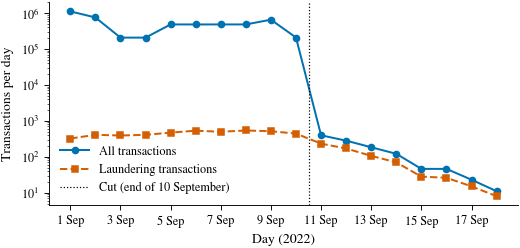

,transactions,laundering,laundering (%)
Timestamp,,,
2022-09-01,1114921,322,0.03
2022-09-02,754449,408,0.05
2022-09-03,207382,391,0.19
2022-09-04,207430,407,0.20
2022-09-05,482650,471,0.10
2022-09-06,482089,531,0.11
2022-09-07,482751,497,0.10
2022-09-08,482773,539,0.11
2022-09-09,654467,514,0.08


In [3]:
raw = pd.read_csv(f'{ROOT}/data/raw/HI-Small_Trans.csv', usecols=['Timestamp', 'Is Laundering'])
day = pd.to_datetime(raw['Timestamp']).dt.normalize()
daily = raw.groupby(day)['Is Laundering'].agg(transactions='size', laundering='sum')
daily['laundering (%)'] = 100 * daily['laundering'] / daily['transactions']

fig, ax = plt.subplots(figsize=(5.5, 2.4))
ax.plot(daily.index, daily['transactions'], marker='o', label='All transactions')
ax.plot(daily.index, daily['laundering'], marker='s', label='Laundering transactions')
ax.axvline(pd.Timestamp(cutoff) - pd.Timedelta(hours=12), color='black', linestyle=':', linewidth=0.8,
           label='Cut (end of 10 September)')                    # between the last kept day and the first dropped one
ax.set_yscale('log')
ax.set_xticks(daily.index[::2])
ax.set_xticklabels([f'{d.day} Sep' for d in daily.index[::2]])
ax.set_xlabel('Day (2022)')
ax.set_ylabel('Transactions per day')
ax.legend(loc='lower left')
fig.savefig(f'{FIGURES}/data_daily_transactions.pdf')
plt.show()
daily

## 4. Graph size

- Nodes = distinct accounts, edges = transactions.
- Parallel edges: several transactions between the same ordered pair of accounts.

In [4]:
accounts = pd.concat([edges['src_account'], edges['dst_account']]).unique()
num_nodes, num_edges = len(accounts), len(edges)

pair_sizes = edges.groupby(['src_account', 'dst_account']).size()    # transactions per ordered pair
num_pairs = len(pair_sizes)
edges_on_repeated_pairs = pair_sizes[pair_sizes > 1].sum()

size = pd.Series({
    'nodes (accounts)': num_nodes,
    'edges (transactions)': num_edges,
    'edges per node': num_edges / num_nodes,
    'connected ordered pairs': num_pairs,
    'edges per connected pair (mean)': num_edges / num_pairs,
    'edges per connected pair (max)': pair_sizes.max(),
    'share of edges with a parallel edge (%)': 100 * edges_on_repeated_pairs / num_edges,
})
size.to_frame('value')

,value
nodes (accounts),"515,070.00"
edges (transactions),"5,077,237.00"
edges per node,9.86
connected ordered pairs,"1,015,069.00"
edges per connected pair (mean),5.00
edges per connected pair (max),89.00
share of edges with a parallel edge (%),91.06


## 5. Self-loops

- A self-loop is a transaction whose sender and receiver are the same account. The graph keeps them.
- We look at their share, at when they occur, at their payment format and at their labels.

In [5]:
edges['self_loop'] = edges['src_account'] == edges['dst_account']
loops = edges[edges['self_loop']]

print(f'self-loops: {len(loops):,} of {num_edges:,} edges ({len(loops) / num_edges:.2%})')
print(f'laundering among self-loops:  {int(loops["label"].sum()):,} ({loops["label"].mean():.4%})')
print(f'laundering among other edges: {int(edges.loc[~edges["self_loop"], "label"].sum()):,} '
      f'({edges.loc[~edges["self_loop"], "label"].mean():.4%})')
print(f'accounts with at least one self-loop: {loops["src_account"].nunique():,} ({loops["src_account"].nunique() / num_nodes:.1%})')

self-loops: 590,819 of 5,077,237 edges (11.64%)
laundering among self-loops:  8 (0.0014%)
laundering among other edges: 4,514 (0.1006%)


accounts with at least one self-loop: 367,753 (71.4%)


In [6]:
# Self-loops per day: the first day is different from the rest
per_day = edges.groupby(edges['Timestamp'].dt.date)['self_loop'].agg(edges='size', self_loops='sum')
per_day['share (%)'] = 100 * per_day['self_loops'] / per_day['edges']
per_day

,edges,self_loops,share (%)
Timestamp,,,
2022-09-01,1114921,507410,45.51
2022-09-02,754449,15480,2.05
2022-09-03,207382,4332,2.09
2022-09-04,207430,4364,2.10
2022-09-05,482650,10399,2.15
2022-09-06,482089,10401,2.16
2022-09-07,482751,10390,2.15
2022-09-08,482773,10408,2.16
2022-09-09,654467,13244,2.02


In [7]:
# Self-loops per payment format
per_format = edges.groupby('Payment Format')['self_loop'].agg(edges='size', self_loops='sum')
per_format['share of the format (%)'] = 100 * per_format['self_loops'] / per_format['edges']
per_format['share of all self-loops (%)'] = 100 * per_format['self_loops'] / len(loops)
per_format.sort_values('self_loops', ascending=False)

,edges,self_loops,share of the format (%),share of all self-loops (%)
Payment Format,,,,
Reinvestment,481056,481056,100.00,81.42
ACH,599689,70954,11.83,12.01
Bitcoin,146091,26317,18.01,4.45
Cheque,1864331,6066,0.33,1.03
Credit Card,1323324,4176,0.32,0.71
Cash,490891,1455,0.30,0.25
Wire,171855,795,0.46,0.13


## 6. Degrees

- Out-degree = transactions an account sends, in-degree = transactions it receives (every edge counts, self-loops too).
- Accounts that never send (or never receive) have degree 0 and are kept in the statistics.

In [8]:
out_degree = edges['src_account'].value_counts().reindex(accounts, fill_value=0)
in_degree = edges['dst_account'].value_counts().reindex(accounts, fill_value=0)
assert out_degree.sum() == in_degree.sum() == num_edges

def describe_degree(degree):
    return pd.Series({
        'accounts with degree 0 (%)': 100 * (degree == 0).mean(),
        'mean': degree.mean(),
        'median': degree.median(),
        '90th percentile': degree.quantile(0.90),
        '99th percentile': degree.quantile(0.99),
        'max': degree.max(),
    })

degree_table = pd.DataFrame({'out-degree': describe_degree(out_degree), 'in-degree': describe_degree(in_degree)})
degree_table

,out-degree,in-degree
accounts with degree 0 (%),3.51,18.34
mean,9.86,9.86
median,2.00,2.00
90th percentile,28.00,29.00
99th percentile,91.00,50.00
max,"168,672.00","1,084.00"


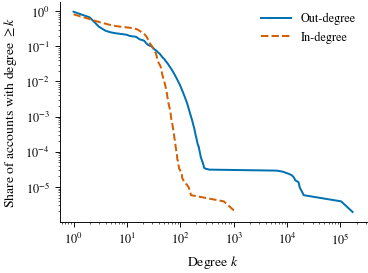

In [9]:
# Share of accounts with degree >= k, on logarithmic axes: a straight, slowly falling line means a heavy tail
def share_at_least(degree):
    values = np.sort(degree[degree > 0].to_numpy())
    distinct, first_position = np.unique(values, return_index=True)
    return distinct, (len(values) - first_position) / len(degree)

fig, ax = plt.subplots(figsize=(3.6, 2.6))
for degree, name in [(out_degree, 'Out-degree'), (in_degree, 'In-degree')]:
    ax.plot(*share_at_least(degree), label=name)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Degree $k$')
ax.set_ylabel('Share of accounts with degree $\\geq k$')
ax.legend()
fig.savefig(f'{FIGURES}/data_degree_distribution.pdf')
plt.show()

## 7. Hubs

- How much of the graph passes through its largest accounts.
- For the ten largest senders: how many transactions, to how many distinct receivers.

In [10]:
def share_of_edges_held_by_top(degree, share_of_accounts):
    top = int(np.ceil(share_of_accounts * len(degree)))
    return 100 * degree.sort_values(ascending=False).iloc[:top].sum() / num_edges

concentration = pd.DataFrame(
    {name: [share_of_edges_held_by_top(degree, share) for share in (0.0001, 0.001, 0.01)]
     for name, degree in [('sent edges (%)', out_degree), ('received edges (%)', in_degree)]},
    index=['top 0.01 % of accounts', 'top 0.1 % of accounts', 'top 1 % of accounts'])
concentration

,sent edges (%),received edges (%)
top 0.01 % of accounts,9.04,0.13
top 0.1 % of accounts,10.69,0.79
top 1 % of accounts,20.99,5.82


In [11]:
# The hubs are a small, separate group: accounts with at least 1,000 transactions in one direction
for name, degree in [('out-degree', out_degree), ('in-degree', in_degree)]:
    large = degree[degree >= 1000]
    print(f'{name} >= 1,000: {len(large)} accounts (smallest {large.min():,}), {large.sum() / num_edges:.1%} of all edges; '
          f'largest {name} below 1,000: {degree[degree < 1000].max():,}')

out-degree >= 1,000: 15 accounts (smallest 6,431), 8.9% of all edges; largest out-degree below 1,000: 351
in-degree >= 1,000: 1 accounts (smallest 1,084), 0.0% of all edges; largest in-degree below 1,000: 653


In [12]:
top_senders = out_degree.sort_values(ascending=False).head(10)
sent_by_top = edges[edges['src_account'].isin(top_senders.index)]

hubs = pd.DataFrame({
    'out-degree': top_senders,
    'distinct receivers': sent_by_top.groupby('src_account')['dst_account'].nunique(),
    'self-loops': sent_by_top.groupby('src_account')['self_loop'].sum(),
    'in-degree': in_degree[top_senders.index],
    'laundering sent': sent_by_top.groupby('src_account')['label'].sum(),
}).loc[top_senders.index]
hubs

,out-degree,distinct receivers,self-loops,in-degree,laundering sent
src_account,,,,,
100428660,168672,14230,0,1084,243
1004286A8,103018,8846,0,653,158
100428978,20497,1776,0,150,29
1004286F0,18663,1575,0,108,21
100428780,17264,1421,0,117,21
1004289C0,16794,1432,0,132,13
100428810,16426,1394,0,114,26
1004287C8,14174,1182,0,103,16
100428738,13756,1136,0,98,23


In [13]:
top_receivers = in_degree.sort_values(ascending=False).head(10)
received_by_top = edges[edges['dst_account'].isin(top_receivers.index)]

pd.DataFrame({
    'in-degree': top_receivers,
    'distinct senders': received_by_top.groupby('dst_account')['src_account'].nunique(),
    'out-degree': out_degree[top_receivers.index],
}).loc[top_receivers.index]

,in-degree,distinct senders,out-degree
dst_account,,,
100428660,1084,545,168672
1004286A8,653,328,103018
80F47A310,159,80,2
100428978,150,75,20497
8018859B0,144,81,67
1004289C0,132,68,16794
100428780,117,61,17264
100428810,114,58,16426
80F0EF460,109,3,90


## 8. Temporal split

- Same cut as `prepare_data.step_graphs`: the time-sorted rows, cut by position at the `split_rows` of `data/feature_meta.json`.
- Each snapshot holds every edge up to its end; only the edges of its own period are evaluated.
- Per split: edges in the snapshot, evaluated edges, their first and last timestamp, laundering among them.

In [14]:
split_rows = json.load(open(f'{ROOT}/data/feature_meta.json'))['split_rows']
assert split_rows['test'] == len(edges)

starts = {'train': 0, 'val': split_rows['train'], 'test': split_rows['val']}
rows = []
for split, start in starts.items():
    evaluated = edges.iloc[start:split_rows[split]]
    rows.append({'split': split,
                 'edges in snapshot': split_rows[split],
                 'evaluated edges': len(evaluated),
                 'first evaluated': evaluated['Timestamp'].iloc[0],
                 'last evaluated': evaluated['Timestamp'].iloc[-1],
                 'laundering': int(evaluated['label'].sum()),
                 'laundering (%)': f"{100 * evaluated['label'].mean():.3f}"})
split_table = pd.DataFrame(rows).set_index('split')
assert split_table['laundering'].sum() == edges['label'].sum()
split_table

,edges in snapshot,evaluated edges,first evaluated,last evaluated,laundering,laundering (%)
split,,,,,,
train,3046342,3046342,2022-09-01 00:00:00,2022-09-06 13:34:00,2297,0.075
val,4061789,1015447,2022-09-06 13:34:00,2022-09-08 16:09:00,1082,0.107
test,5077237,1015448,2022-09-08 16:09:00,2022-09-10 23:59:00,1143,0.113
